# Short-List Promising Models & Fine-Tune the System

## Load the Prepared Data

The preprocessing transformers and `build_preprocessor()` are defined in `preparation.py`, which both notebooks import. Because the classes are in a module instead of the Preparation notebook, `preprocessor.pkl` can be loaded here directly without rerunning the Preparation notebook.

This cell gives this notebook:

- `X_train`, `y_train`: the preprocessed training features (57 × 160) and labels, ready for training.
- `train_set`: the raw training set, for pipelines that include `build_preprocessor()` so preprocessing is refit inside each cross-validation fold.
- `preprocessor` and `build_preprocessor()`: the fitted preprocessor loaded from `preprocessor.pkl` and a function that builds a new unfitted one.

The test set is not loaded here, so it stays untouched until the final evaluation.

In [5]:
import pickle

import pandas as pd

from preparation import build_preprocessor

train_set = pd.read_parquet("train_set.parquet")
y_train = train_set["early_spring"]

with open("preprocessor.pkl", "rb") as file:
    preprocessor = pickle.load(file)

X_train = preprocessor.transform(train_set)

print("Training shape:", X_train.shape)

Training shape: (57, 160)


In [44]:
from sklearn.metrics import f1_score, confusion_matrix, make_scorer, precision_score, recall_score
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}


def evaluate_classifier(model):
    model.fit(X_train, y_train)
    train_predictions = model.predict(X_train)
    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
    )
    return {
        "train_f1": f1_score(y_train, train_predictions, zero_division=0),
        "cv_recall": cv_results["test_recall"].mean(),
        "cv_precision": cv_results["test_precision"].mean(),
        "cv_f1": cv_results["test_f1"].mean(),
    }

In [8]:
dt_cls = DecisionTreeClassifier(random_state=42)
dt_results = evaluate_classifier(dt_cls)
dt_results

{'train_f1': 1.0,
 'cv_recall': np.float64(0.2),
 'cv_precision': np.float64(0.16666666666666666),
 'cv_f1': np.float64(0.1688888888888889)}

In [9]:
rf_cls = RandomForestClassifier(random_state=42)
rf_results = evaluate_classifier(rf_cls)
rf_results

{'train_f1': 1.0,
 'cv_recall': np.float64(0.06666666666666667),
 'cv_precision': np.float64(0.2),
 'cv_f1': np.float64(0.1)}

In [10]:
lin_svm_cls = LinearSVC(random_state=42)
lin_svm_results = evaluate_classifier(lin_svm_cls)
lin_svm_results

{'train_f1': 1.0,
 'cv_recall': np.float64(0.4999999999999999),
 'cv_precision': np.float64(0.27666666666666667),
 'cv_f1': np.float64(0.3555555555555555)}

In [11]:
svm_rbf = SVC(kernel="rbf", random_state=42)
svm_results = evaluate_classifier(svm_rbf)
svm_results

{'train_f1': 0.5263157894736842,
 'cv_recall': np.float64(0.0),
 'cv_precision': np.float64(0.0),
 'cv_f1': np.float64(0.0)}

In [12]:
mlp_cls = MLPClassifier(hidden_layer_sizes=(50, 20), random_state=42)
mlp_results = evaluate_classifier(mlp_cls)
mlp_results

{'train_f1': 1.0,
 'cv_recall': np.float64(0.06666666666666667),
 'cv_precision': np.float64(0.06666666666666667),
 'cv_f1': np.float64(0.06666666666666667)}

In [13]:
logred_cls = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logred_results = evaluate_classifier(logred_cls)
logred_results

{'train_f1': 1.0,
 'cv_recall': np.float64(0.29999999999999993),
 'cv_precision': np.float64(0.36666666666666664),
 'cv_f1': np.float64(0.32)}

In [14]:
# Gradient Boosting Classifier
gb_cls = GradientBoostingClassifier(random_state=42)
gb_results = evaluate_classifier(gb_cls)
gb_results

{'train_f1': 1.0,
 'cv_recall': np.float64(0.4),
 'cv_precision': np.float64(0.3466666666666667),
 'cv_f1': np.float64(0.36095238095238097)}

## Shortlist Findings

The base models were compared using five-fold stratified cross-validation. The reported `cv_recall`, `cv_precision`, and `cv_f1` values are averages across the validation folds for the positive class, `True` (early Spring). The `train_f1` value is only included to check for overfitting and is not used to select the models.

| Model | CV recall | CV precision | CV F1 | Training F1 |
|---|---:|---:|---:|---:|
| Decision tree | 0.20 | 0.167 | 0.169 | 1.000 |
| Random forest | 0.067 | 0.200 | 0.100 | 1.000 |
| Linear SVM | 0.500 | 0.277 | 0.356 | 1.000 |
| RBF SVM | 0.000 | 0.000 | 0.000 | 0.526 |
| MLP neural network | 0.067 | 0.067 | 0.067 | 1.000 |
| Logistic Regression | 0.300 | 0.370 | 0.320 | 1.000 |
| Gradient Boosting | 0.400 | 0.347 | 0.361 | 1.000 |

Because missing an early Spring is the most costly error, recall is the primary comparison metric. The Linear SVM has the strongest recall and F1, and Logistic Regression has the strongest precision and the second highest F1. The large gap between training F1 and cross-validation F1 for most models indicates overfitting, so the cross-validation results are more informative than training performance. The estimates are uncertain because the training set contains only 14 early-Spring examples. Each validation fold contains only about two or three positive examples, so the best model may change during fine-tuning.

## Models for Fine-Tuning

The three models selected to continue with are:

1. **LinearSVC:** Best early-Spring recall and best cross-validation F1.
2. **LogisticRegression:** Best precision and a competitive F1 score. Its `class_weight="balanced"` setting is used to addresses the class imbalance.
3. **RandomForestClassifier:** Nonlinear ensemble comparison, even though its recall is currently weak.

During fine-tuning, these models should be evaluated using recall, precision, and F1 for the early-Spring class. Gradient Boosting will also be tuned as the additional ensemble model.

For fine-tuning, preprocessing should be included inside each model pipeline and refit within every cross-validation fold. The current shortlist evaluates the already-preprocessed `X_train`. The next step should instead use `train_set`, `build_preprocessor()`, and a pipeline so imputation and scaling do not use information from the validation fold.

## Fine-Tuning The System

In [37]:
# Use the raw training features so preprocessing happens within each CV fold
X_train_raw = train_set.drop(columns=["early_spring"])

linear_svc_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LinearSVC(max_iter=20000, random_state=42))
])

linear_svc_params = {
    "preprocessor__scale": [StandardScaler(), RobustScaler()],
    "preprocessor__reduce": [
        "passthrough",
        SelectKBest(score_func=f_classif, k=10),
        SelectKBest(score_func=f_classif, k=20),
        SelectKBest(score_func=f_classif, k=30),
        SelectKBest(score_func=f_classif, k="all"),
    ],
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__loss": ["hinge", "squared_hinge"],
}

linear_svc_search = RandomizedSearchCV(
    estimator=linear_svc_pipeline,
    param_distributions=linear_svc_params,
    n_iter=30,
    scoring=scoring,
    refit="recall",
    cv=cv,
    random_state=42,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

linear_svc_search.fit(X_train_raw, y_train)

print("Best cross-validation recall:", linear_svc_search.best_score_)
print("Best parameters:")
print(linear_svc_search.best_params_)

linear_svc_results = (
    pd.DataFrame(linear_svc_search.cv_results_)
    .sort_values("rank_test_recall")
)

display(
    linear_svc_results[
        [
            "mean_test_recall",
            "mean_test_precision",
            "mean_test_f1",
            "mean_train_recall",
            "mean_train_f1",
            "params",
        ]
    ].head(10)
)

Best cross-validation recall: 0.8666666666666666
Best parameters:
{'preprocessor__scale': StandardScaler(), 'preprocessor__reduce': SelectKBest(k=20), 'classifier__loss': 'hinge', 'classifier__class_weight': 'balanced', 'classifier__C': 0.001}


,mean_test_recall,mean_test_precision,mean_test_f1,mean_train_recall,mean_train_f1,params
0,0.866667,0.353810,0.495960,0.965152,0.671338,"{'preprocessor__scale': StandardScaler(), 'pre..."
1,0.800000,0.392857,0.516032,0.946970,0.726178,"{'preprocessor__scale': StandardScaler(), 'pre..."
23,0.666667,0.305476,0.406710,1.000000,0.728012,"{'preprocessor__scale': StandardScaler(), 'pre..."
26,0.600000,0.315476,0.388456,1.000000,0.778497,"{'preprocessor__scale': StandardScaler(), 'pre..."
27,0.433333,0.500000,0.427619,1.000000,1.000000,"{'preprocessor__scale': RobustScaler(), 'prepr..."
3,0.433333,0.500000,0.427619,1.000000,1.000000,"{'preprocessor__scale': RobustScaler(), 'prepr..."
4,0.433333,0.266667,0.307778,1.000000,0.810074,"{'preprocessor__scale': StandardScaler(), 'pre..."
14,0.400000,0.173810,0.234921,0.909091,0.771033,"{'preprocessor__scale': RobustScaler(), 'prepr..."
9,0.333333,0.157143,0.203175,0.927273,0.787315,"{'preprocessor__scale': RobustScaler(), 'prepr..."
25,0.300000,0.266667,0.274286,1.000000,1.000000,"{'preprocessor__scale': StandardScaler(), 'pre..."


The tuned LinearSVC model achieved a cross-validation recall of 0.867, precision of 0.354, and F1 score of 0.496. The best configuration used standard scaling, selected 20 features, used balanced class weights, and had a low regularization parameter (C = 0.001). The high recall means it identified most early-Spring years in the validation folds, but its lower precision means it also produced false positive predictions. Training recall was 0.965, suggesting some overfitting might remain.

In [49]:
log_reg_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(max_iter=5000, random_state=42))
])

log_reg_params = {
    # Preprocessing hyperparameters
    "preprocessor__scale": [StandardScaler(), RobustScaler()],
    "preprocessor__reduce": [
        "passthrough",
        SelectKBest(score_func=f_classif, k=10),
        SelectKBest(score_func=f_classif, k=20),
        SelectKBest(score_func=f_classif, k=30),
        SelectKBest(score_func=f_classif, k="all"),
    ],

    # Logistic Regression hyperparameters
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["liblinear", "lbfgs"],
}

log_reg_search = RandomizedSearchCV(
    estimator=log_reg_pipeline,
    param_distributions=log_reg_params,
    n_iter=30,
    scoring=scoring,
    refit="recall",
    cv=cv,
    random_state=42,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

log_reg_search.fit(X_train_raw, y_train)

print("Best cross-validation recall:", log_reg_search.best_score_)
print("Best parameters:")
print(log_reg_search.best_params_)

log_reg_results = (
    pd.DataFrame(log_reg_search.cv_results_)
    .sort_values("rank_test_recall")
)

display(
    log_reg_results[
        [
            "mean_test_recall",
            "mean_test_precision",
            "mean_test_f1",
            "mean_train_recall",
            "mean_train_f1",
            "params",
        ]
    ].head(10)
)

Best cross-validation recall: 0.8666666666666666
Best parameters:
{'preprocessor__scale': StandardScaler(), 'preprocessor__reduce': SelectKBest(k=20), 'classifier__solver': 'liblinear', 'classifier__class_weight': 'balanced', 'classifier__C': 0.001}


,mean_test_recall,mean_test_precision,mean_test_f1,mean_train_recall,mean_train_f1,params
0,0.866667,0.353810,0.495960,0.965152,0.678600,"{'preprocessor__scale': StandardScaler(), 'pre..."
1,0.800000,0.412857,0.530317,0.946970,0.730479,"{'preprocessor__scale': StandardScaler(), 'pre..."
3,0.533333,0.540000,0.480000,1.000000,0.983304,"{'preprocessor__scale': RobustScaler(), 'prepr..."
4,0.500000,0.303810,0.354444,0.981818,0.762667,"{'preprocessor__scale': StandardScaler(), 'pre..."
9,0.400000,0.173810,0.234921,0.909091,0.766110,"{'preprocessor__scale': RobustScaler(), 'prepr..."
29,0.400000,0.183333,0.246032,0.909091,0.776853,"{'preprocessor__scale': RobustScaler(), 'prepr..."
14,0.366667,0.216667,0.269841,0.821212,0.691858,"{'preprocessor__scale': RobustScaler(), 'prepr..."
27,0.366667,0.466667,0.374286,1.000000,1.000000,"{'preprocessor__scale': RobustScaler(), 'prepr..."
23,0.366667,0.256667,0.290476,0.875758,0.705127,"{'preprocessor__scale': StandardScaler(), 'pre..."
12,0.366667,0.313333,0.326667,0.963636,0.818613,"{'preprocessor__scale': StandardScaler(), 'pre..."


The tuned Logistic Regression model also achieved a cross-validation recall of 0.867, with a precision of 0.354 and an F1 score of 0.496. Its best configuration used standard scaling, selected 20 features, used balanced class weights, and had C = 0.001 with the liblinear solver. These results are identical to the best LinearSVC results, so neither model shows a clear advantage over the other so far. Both models have high recall but relatively low precision, so they catch most early-Spring years but also incorrectly flag some years as early Spring.

I also tried tuning Logistic Regression using F1 instead of recall as the selection metric. This resulted in higher cross-validation precision (0.687 vs. 0.354) and a slightly higher F1 score (0.544 vs. 0.496). However, recall decreased from 0.867 to 0.567, meaning the model missed more actual early-Spring years. Because of this trade-off, the original model will be kept which identifies more early-Spring years.

In [39]:
random_forest_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", RandomForestClassifier(random_state=42))
])

random_forest_params = {
    # Preprocessing hyperparameters
    "preprocessor__scale": [StandardScaler(), RobustScaler()],
    "preprocessor__reduce": [
        "passthrough",
        SelectKBest(score_func=f_classif, k=10),
        SelectKBest(score_func=f_classif, k=20),
        SelectKBest(score_func=f_classif, k=30),
        SelectKBest(score_func=f_classif, k="all"),
    ],

    # Random Forest hyperparameters
    "classifier__n_estimators": [100, 200, 400, 600],
    "classifier__max_depth": [None, 3, 5, 10, 20],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 4, 6],
    "classifier__max_features": ["sqrt", "log2", 0.5],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"],
}

random_forest_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=random_forest_params,
    n_iter=30,
    scoring=scoring,
    refit="recall",
    cv=cv,
    random_state=42,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

random_forest_search.fit(X_train_raw, y_train)

print("Best cross-validation recall:", random_forest_search.best_score_)
print("Best parameters:")
print(random_forest_search.best_params_)

random_forest_results = (
    pd.DataFrame(random_forest_search.cv_results_)
    .sort_values("rank_test_recall")
)

display(
    random_forest_results[
        [
            "mean_test_recall",
            "mean_test_precision",
            "mean_test_f1",
            "mean_train_recall",
            "mean_train_f1",
            "params",
        ]
    ].head(10)
)

Best cross-validation recall: 0.4
Best parameters:
{'preprocessor__scale': RobustScaler(), 'preprocessor__reduce': SelectKBest(k=20), 'classifier__n_estimators': 600, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}


,mean_test_recall,mean_test_precision,mean_test_f1,mean_train_recall,mean_train_f1,params
1,0.400000,0.280000,0.313333,0.983333,0.895231,"{'preprocessor__scale': RobustScaler(), 'prepr..."
4,0.400000,0.433333,0.366667,0.983333,0.909971,"{'preprocessor__scale': RobustScaler(), 'prepr..."
0,0.333333,0.400000,0.313333,0.965152,0.873715,"{'preprocessor__scale': StandardScaler(), 'pre..."
15,0.333333,0.400000,0.313333,0.965152,0.873715,"{'preprocessor__scale': RobustScaler(), 'prepr..."
5,0.333333,0.352381,0.286667,0.983333,0.867527,"{'preprocessor__scale': StandardScaler(), 'pre..."
14,0.333333,0.283333,0.292698,0.946970,0.787624,"{'preprocessor__scale': RobustScaler(), 'prepr..."
6,0.266667,0.280000,0.260000,0.983333,0.887897,"{'preprocessor__scale': StandardScaler(), 'pre..."
21,0.266667,0.300000,0.280000,0.983333,0.860194,"{'preprocessor__scale': RobustScaler(), 'prepr..."
12,0.266667,0.216667,0.226032,0.983333,0.846655,"{'preprocessor__scale': RobustScaler(), 'prepr..."
29,0.266667,0.266667,0.260952,0.928788,0.851534,"{'preprocessor__scale': RobustScaler(), 'prepr..."


The tuned Random Forest model achieved a cross-validation recall of 0.400, precision of 0.280, and F1 score of 0.313. The best configuration used robust scaling, selected 20 features, and used 600 trees with a maximum depth of 10, balanced class weights, and minimum sample settings to restrict tree growth. Its training recall was 0.983 which is much higher than its validation recall, suggesting significant overfitting. Its validation performance was also weaker than the tuned LinearSVC and Logistic Regression models, so Random Forest does not appear to be the strongest option so far.

In [40]:
gradient_boosting_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

gradient_boosting_params = {
    # Preprocessing hyperparameters
    "preprocessor__scale": [StandardScaler(), RobustScaler()],
    "preprocessor__reduce": [
        "passthrough",
        SelectKBest(score_func=f_classif, k=10),
        SelectKBest(score_func=f_classif, k=20),
        SelectKBest(score_func=f_classif, k=30),
        SelectKBest(score_func=f_classif, k="all"),
    ],

    # Gradient Boosting hyperparameters
    "classifier__n_estimators": [50, 100, 200, 300],
    "classifier__learning_rate": [0.01, 0.03, 0.1, 0.2],
    "classifier__max_depth": [1, 2, 3, 5],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4, 6],
    "classifier__subsample": [0.6, 0.8, 1.0],
    "classifier__max_features": [None, "sqrt", "log2"],
}

gradient_boosting_search = RandomizedSearchCV(
    estimator=gradient_boosting_pipeline,
    param_distributions=gradient_boosting_params,
    n_iter=30,
    scoring=scoring,
    refit="recall",
    cv=cv,
    random_state=42,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise",
)

gradient_boosting_search.fit(X_train_raw, y_train)

print("Best cross-validation recall:", gradient_boosting_search.best_score_)
print("Best parameters:")
print(gradient_boosting_search.best_params_)

gradient_boosting_results = (
    pd.DataFrame(gradient_boosting_search.cv_results_)
    .sort_values("rank_test_recall")
)

display(
    gradient_boosting_results[
        [
            "mean_test_recall",
            "mean_test_precision",
            "mean_test_f1",
            "mean_train_recall",
            "mean_train_f1",
            "params",
        ]
    ].head(10)
)

Best cross-validation recall: 0.29999999999999993
Best parameters:
{'preprocessor__scale': StandardScaler(), 'preprocessor__reduce': SelectKBest(k=30), 'classifier__subsample': 0.8, 'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 1, 'classifier__learning_rate': 0.2}


,mean_test_recall,mean_test_precision,mean_test_f1,mean_train_recall,mean_train_f1,params
14,0.300000,0.280000,0.280000,1.0,1.0,"{'preprocessor__scale': RobustScaler(), 'prepr..."
2,0.300000,0.500000,0.347619,1.0,1.0,"{'preprocessor__scale': StandardScaler(), 'pre..."
4,0.300000,0.233333,0.248889,1.0,1.0,"{'preprocessor__scale': StandardScaler(), 'pre..."
23,0.266667,0.233333,0.235556,1.0,1.0,"{'preprocessor__scale': RobustScaler(), 'prepr..."
26,0.200000,0.280000,0.200000,1.0,1.0,"{'preprocessor__scale': StandardScaler(), 'pre..."
5,0.200000,0.300000,0.214286,1.0,1.0,"{'preprocessor__scale': RobustScaler(), 'prepr..."
25,0.200000,0.216667,0.203810,1.0,1.0,"{'preprocessor__scale': RobustScaler(), 'prepr..."
22,0.200000,0.280000,0.200000,1.0,1.0,"{'preprocessor__scale': StandardScaler(), 'pre..."
10,0.200000,0.123810,0.146667,1.0,1.0,"{'preprocessor__scale': StandardScaler(), 'pre..."
27,0.166667,0.150000,0.157143,1.0,1.0,"{'preprocessor__scale': RobustScaler(), 'prepr..."


The tuned Gradient Boosting model achieved a cross-validation recall of 0.300, precision of 0.280, and F1 score of 0.280 for the current configuration. The parameters used standard scaling, selected 30 features, and used 100 estimators with a learning rate of 0.2 and a maximum depth of 1. The model has a training recall and F1 score of 1.0 anmd its validation scores are much lower, again suggesting significant overfitting. Its validation performance is also weaker than the tuned LinearSVC and Logistic Regression models, so Gradient Boosting doesn't look like the strongest option based on these results.

In [41]:
# Compare the best configuration from each tuned model
searches = {
    "LinearSVC": linear_svc_search,
    "Logistic Regression": log_reg_search,
    "Random Forest": random_forest_search,
    "Gradient Boosting": gradient_boosting_search,
}

comparison = []

for name, search in searches.items():
    idx = search.best_index_
    results = search.cv_results_

    comparison.append({
        "Model": name,
        "CV Recall": results["mean_test_recall"][idx],
        "CV Precision": results["mean_test_precision"][idx],
        "CV F1": results["mean_test_f1"][idx],
        "Train Recall": results["mean_train_recall"][idx],
        "Train F1": results["mean_train_f1"][idx],
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    "CV Recall", ascending=False
).reset_index(drop=True)

display(comparison_df.round(3))

,Model,CV Recall,CV Precision,CV F1,Train Recall,Train F1
0,LinearSVC,0.867,0.354,0.496,0.965,0.671
1,Logistic Regression,0.867,0.354,0.496,0.965,0.679
2,Random Forest,0.400,0.280,0.313,0.983,0.895
3,Gradient Boosting,0.300,0.500,0.348,1.000,1.000


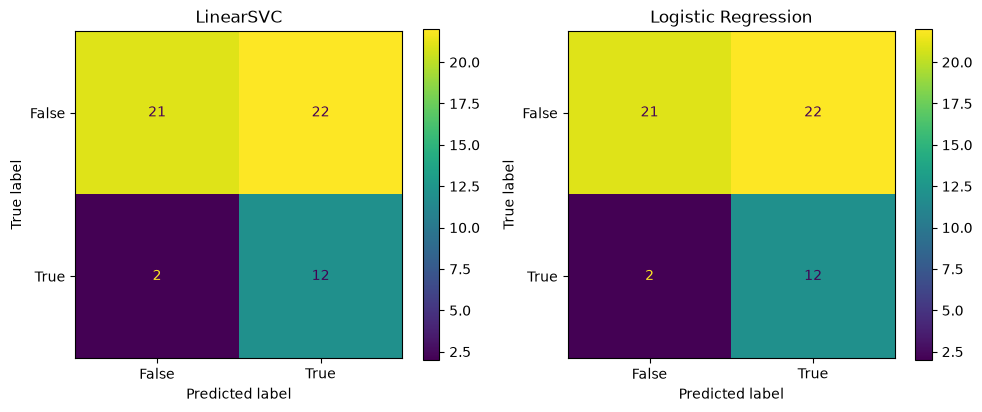

In [43]:
best_linear_svc = linear_svc_search.best_estimator_
best_log_reg = log_reg_search.best_estimator_

linear_svc_preds = cross_val_predict(
    best_linear_svc, X_train_raw, y_train, cv=cv
)

log_reg_preds = cross_val_predict(
    best_log_reg, X_train_raw, y_train, cv=cv
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    linear_svc_preds,
    labels=[False, True],
    ax=axes[0]
)
axes[0].set_title("LinearSVC")

ConfusionMatrixDisplay.from_predictions(
    y_train,
    log_reg_preds,
    labels=[False, True],
    ax=axes[1]
)
axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()

The confusion matrices for LinearSVC and Logistic Regression are identical. Both models correctly identified 12 early-Spring years and missed 2, giving them a high recall. However, both also produced 22 false positives, meaning they predicted early Spring for many years that did not qualify. They correctly classified 21 years as not early Spring. These results show that both models identify most actual early-Spring years but produce a high number of false alarms. Since their confusion matrices and cross-validation metrics are the same, neither model has shown a clear advantage over the other so far.

In [45]:
# Get out-of-fold predicted probabilities from tuned Logistic Regression
log_reg_probs = cross_val_predict(
    log_reg_search.best_estimator_,
    X_train_raw,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

threshold_results = []

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    predictions = log_reg_probs >= threshold

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[False, True]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,Threshold,True Positives,False Positives,True Negatives,False Negatives,Precision,Recall,F1
0,0.3,14,43,0,0,0.246,1.000,0.394
1,0.4,14,43,0,0,0.246,1.000,0.394
2,0.5,12,22,21,2,0.353,0.857,0.500
3,0.6,0,0,43,14,0.000,0.000,0.000
4,0.7,0,0,43,14,0.000,0.000,0.000
5,0.8,0,0,43,14,0.000,0.000,0.000


Testing thresholds from 0.3 to 0.8 showed a big change in the model's predictions. At thresholds of 0.3 and 0.4, the model predicted every year as early Spring, while thresholds of 0.6 and above resulted in no positive predictions. The default threshold of 0.5 performed much better than these alternatives. These results suggest that adjusting the threshold may involve a significant trade-off between false positives and false negatives, so smaller threshold increments are worth investigating.

In [46]:
fine_threshold_results = []

for threshold in [0.50, 0.51, 0.52, 0.53, 0.54,
                   0.55, 0.56, 0.57, 0.58, 0.59]:
    predictions = log_reg_probs >= threshold

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[False, True]
    ).ravel()

    fine_threshold_results.append({
        "Threshold": threshold,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
    })

fine_threshold_df = pd.DataFrame(fine_threshold_results)
display(fine_threshold_df.round(3))

,Threshold,True Positives,False Positives,True Negatives,False Negatives,Precision,Recall,F1
0,0.50,12,22,21,2,0.353,0.857,0.500
1,0.51,2,6,37,12,0.250,0.143,0.182
2,0.52,0,1,42,14,0.000,0.000,0.000
3,0.53,0,0,43,14,0.000,0.000,0.000
4,0.54,0,0,43,14,0.000,0.000,0.000
5,0.55,0,0,43,14,0.000,0.000,0.000
6,0.56,0,0,43,14,0.000,0.000,0.000
7,0.57,0,0,43,14,0.000,0.000,0.000
8,0.58,0,0,43,14,0.000,0.000,0.000
9,0.59,0,0,43,14,0.000,0.000,0.000


Testing thresholds between 0.50 and 0.59 showed that even a small increase in the threshold significantly changed the predictions. At 0.51, recall dropped to 0.143, and at 0.52 and above, the model did not identify any early-Spring years. The default threshold of 0.50 had the best F1 score (0.500) and recall (0.857) among the tested thresholds. So increasing the threshold does not provide any useful improvement, and the default threshold will be kept.

## Final Model Selection

After comparing the four tuned models, Logistic Regression will be chosen as the final model. It achieved the highest cross-validation recall (0.867), along with an F1 score of 0.496. Its results were identical to LinearSVC, but Logistic Regression also provides probability estimates, which allowed for experimentation with different classification thresholds. Although the model produces a relatively high number of false positives, it identifies most actual early-Spring years. Its performance will be evaluated on the held-out test set next.

In [ ]:
# Load the test set and evaluate the final model
test_set = pd.read_parquet("test_set.parquet")

X_test = test_set.drop(columns=["early_spring"])
y_test = test_set["early_spring"]

In [ ]:
final_model = log_reg_search.best_estimator_

In [ ]:
test_preds = final_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, test_preds))
print("Precision:", precision_score(y_test, test_preds, zero_division=0))
print("Recall:", recall_score(y_test, test_preds, zero_division=0))
print("F1 Score:", f1_score(y_test, test_preds, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, test_preds, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_preds, labels=[False, True]))

In [ ]:
# Save the final model
with open("final_model.pkl", "wb") as file:
    pickle.dump(final_model, file)